## <font color='blue'>Neural net experiments</font>

In [1]:
%matplotlib inline
import numpy as np
import torch
import matplotlib.pyplot as plt

### <font color='blue'>1. Various helper functions</font>

This function loads in a data set

In [2]:
def load_data(datafile):
    data = np.loadtxt(datafile)
    n,p = data.shape
    rawx = data[:,0:2]
    rawy = data[:,2]
    x = torch.tensor(rawx, dtype=torch.float)
    y = torch.reshape(torch.tensor((rawy+1.0)/2.0, dtype=torch.float), [n,1])
    return x,y

This function plots the data set

In [3]:
def plot_data(x,y):
    x_min = min(x[:,0]) - 1
    x_max = max(x[:,0]) + 1
    y_min = min(x[:,1]) - 1
    y_max = max(x[:,1]) + 1
    pos = (torch.squeeze(y) == 1)
    neg = (torch.squeeze(y) == 0)
    plt.plot(x[pos,0], x[pos,1], 'ro')
    plt.plot(x[neg,0], x[neg,1], 'k^')
    plt.xlim(x_min,x_max)
    plt.ylim(y_min,y_max)
    plt.show()

This function plots a decision boundary as well as the data points

In [21]:
def plot_boundary(x,y,model, title=""):
    
    x_min = min(x[:,0]) - 1
    x_max = max(x[:,0]) + 1
    y_min = min(x[:,1]) - 1
    y_max = max(x[:,1]) + 1

    delta = 0.05
    xx, yy = np.meshgrid(np.arange(x_min, x_max, delta), np.arange(y_min, y_max, delta))
    grid = np.c_[xx.ravel(), yy.ravel()]
    gn, gp = grid.shape
    Z = np.zeros(gn)
    for i in range(gn):
        pred = model(torch.tensor(grid[i,:], dtype=torch.float))
        Z[i] = int(pred > 0.5)

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.pcolormesh(xx, yy, Z, cmap=plt.cm.PRGn, vmin=-3, vmax=3)

    # Plot also the training points
    pos = (torch.squeeze(y) == 1)
    neg = (torch.squeeze(y) == 0)
    plt.plot(x[pos,0], x[pos,1], 'ro')
    plt.plot(x[neg,0], x[neg,1], 'k^')

    plt.xlim(x_min,x_max)
    plt.ylim(y_min,y_max)
    plt.title(title)
    plt.show()

This function computes the error rate of the predicted labels `y1` given the true labels `y2`.


In [5]:
def error_rate(y1, y2):
    sum = 0.0
    for i in range(0,y1.size()[0]):
        sum += ((y1[i]-0.5) * (y2[i]-0.5) <= 0.0)
    return int(sum)

### <font color='blue'>2. Experiments with toy data</font>

Let's load in one of the data sets and print it.

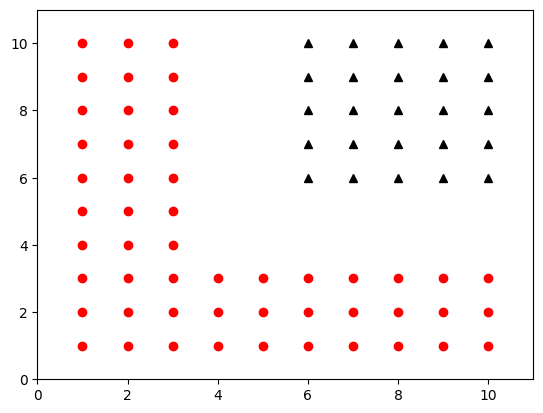

In [102]:
x,y = load_data('data4.txt')
plot_data(x,y)

Next, we train a feedforward net on it. This takes many iterations of gradient descent (backpropagation). We'll print the status every 1000 iterations.

In [105]:
# Now train a neural net
#
# d is input dimension
# H is hidden dimension
d = 2
H = 3

# Use the nn package to define our model as a sequence of layers. nn.Sequential
# is a Module which contains other Modules, and applies them in sequence to
# produce its output. Each Linear Module computes output from input using a
# linear function, and holds internal Tensors for its weight and bias.
model = torch.nn.Sequential(
    torch.nn.Linear(d, H),
    torch.nn.ReLU(),
    torch.nn.Linear(H, 1),
    torch.nn.Sigmoid()
)

# The nn package also contains definitions of popular loss functions; in this
# case we will use binary cross entropy (BCE) as our loss function.
loss_fn = torch.nn.BCELoss()

prev_loss = 1.0
learning_rate = 1.25
done = False
t = 1
tol = 1e-4
while not(done):
    # Forward pass: compute predicted y by passing x to the model. Module objects
    # override the __call__ operator so you can call them like functions. When
    # doing so you pass a Tensor of input data to the Module and it produces
    # a Tensor of output data.
    y_pred = model(x)
    t = t+1
    # Compute and print loss. We pass Tensors containing the predicted and true
    # values of y, and the loss function returns a Tensor containing the
    # loss.
    loss = loss_fn(y_pred, y)
    if t % 1000 == 0:
        print('Iteration %d: loss %0.5f errors %d' % 
              (t, loss.item(), error_rate(y_pred, y)))
        if (prev_loss - loss.item() < tol):
            done = True
        prev_loss = loss.item()

    # Zero the gradients before running the backward pass.
    model.zero_grad()

    # Backward pass: compute gradient of the loss with respect to all the learnable
    # parameters of the model. Internally, the parameters of each Module are stored
    # in Tensors with requires_grad=True, so this call will compute gradients for
    # all learnable parameters in the model.
    loss.backward()

    # Update the weights using gradient descent. Each parameter is a Tensor, so
    # we can access its gradients like we did before.
    with torch.no_grad():
        for param in model.parameters():
            param -= learning_rate * (1.0/np.sqrt(t)) * param.grad
print("Number of training errors:", error_rate(model(x), y))

Iteration 1000: loss 0.11946 errors 2
Iteration 2000: loss 0.04664 errors 0
Iteration 3000: loss 0.03113 errors 0
Iteration 4000: loss 0.02408 errors 0
Iteration 5000: loss 0.01998 errors 0
Iteration 6000: loss 0.01726 errors 0
Iteration 7000: loss 0.01532 errors 0
Iteration 8000: loss 0.01384 errors 0
Iteration 9000: loss 0.01268 errors 0
Iteration 10000: loss 0.01174 errors 0
Iteration 11000: loss 0.01096 errors 0
Iteration 12000: loss 0.01030 errors 0
Iteration 13000: loss 0.00974 errors 0
Iteration 14000: loss 0.00909 errors 0
Iteration 15000: loss 0.00866 errors 0
Iteration 16000: loss 0.00827 errors 0
Iteration 17000: loss 0.00793 errors 0
Iteration 18000: loss 0.00763 errors 0
Iteration 19000: loss 0.00735 errors 0
Iteration 20000: loss 0.00710 errors 0
Iteration 21000: loss 0.00687 errors 0
Iteration 22000: loss 0.00666 errors 0
Iteration 23000: loss 0.00646 errors 0
Iteration 24000: loss 0.00628 errors 0
Iteration 25000: loss 0.00612 errors 0
Iteration 26000: loss 0.00596 erro

Now let's see what kind of a boundary we got!

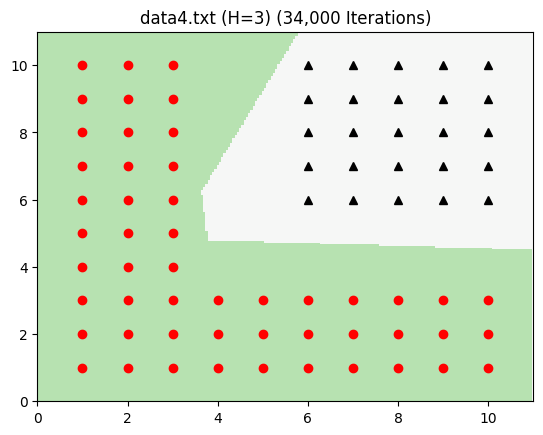

In [106]:
plot_boundary(x,y,model,f'data4.txt (H=3) (34,000 Iterations)')

### <font color='blue'>3. A different data set</font>

The code in the next cell generates a data set of 800 points in which the labels are noisy.

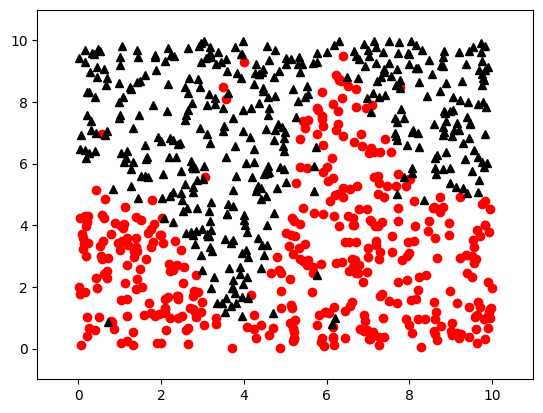

In [114]:
n = 800
np.random.seed(0)
X_train = np.random.rand(n,2)
x1 = X_train[:,0]
x2 = X_train[:,1]
y_train = ((np.exp(-((x1-0.5)*6)**2)*2*((x1-0.5)*6)+1)/2-x2)>0 

idx = np.random.choice(range(n),size=(int(n*0.03),))
y_train[idx] = ~y_train[idx]
x = torch.tensor(X_train, dtype=torch.float) * 10
y = torch.reshape(torch.tensor(y_train, dtype=torch.float), [n,1])
plot_data(x,y)

<font color='magenta'>Define a neural net with <b>two</b> hidden layers, each containing the same number of nodes. <em>Hint:</em> Start with the code above and just make a small tweak to it.</font>

<font color='magenta'>Train the net a few times, and print the decision boundary for the best (lowest-error) model that you find.</font>

In [120]:
# Now train a neural net
#
# d is input dimension
# H is hidden dimension
d = 2
H = 6

# Use the nn package to define our model as a sequence of layers. nn.Sequential
# is a Module which contains other Modules, and applies them in sequence to
# produce its output. Each Linear Module computes output from input using a
# linear function, and holds internal Tensors for its weight and bias.
model = torch.nn.Sequential(
    torch.nn.Linear(d, H),
    torch.nn.ReLU(),
    torch.nn.Linear(H, H),
    torch.nn.ReLU(),
    torch.nn.Linear(H, 1),
    torch.nn.Sigmoid()
)

# The nn package also contains definitions of popular loss functions; in this
# case we will use binary cross entropy (BCE) as our loss function.
loss_fn = torch.nn.BCELoss()

prev_loss = 1.0
learning_rate = 1.25
done = False
t = 1
tol = 1e-4
while not(done):
    # Forward pass: compute predicted y by passing x to the model. Module objects
    # override the __call__ operator so you can call them like functions. When
    # doing so you pass a Tensor of input data to the Module and it produces
    # a Tensor of output data.
    y_pred = model(x)
    t = t+1
    # Compute and print loss. We pass Tensors containing the predicted and true
    # values of y, and the loss function returns a Tensor containing the
    # loss.
    loss = loss_fn(y_pred, y)
    if t % 1000 == 0:
        print('Iteration %d: loss %0.5f errors %d' % 
              (t, loss.item(), error_rate(y_pred, y)))
        if (prev_loss - loss.item() < tol):
            done = True
        prev_loss = loss.item()

    # Zero the gradients before running the backward pass.
    model.zero_grad()

    # Backward pass: compute gradient of the loss with respect to all the learnable
    # parameters of the model. Internally, the parameters of each Module are stored
    # in Tensors with requires_grad=True, so this call will compute gradients for
    # all learnable parameters in the model.
    loss.backward()

    # Update the weights using gradient descent. Each parameter is a Tensor, so
    # we can access its gradients like we did before.
    with torch.no_grad():
        for param in model.parameters():
            param -= learning_rate * (1.0/np.sqrt(t)) * param.grad
print("Number of training errors:", error_rate(model(x), y))

Iteration 1000: loss 0.41481 errors 144
Iteration 2000: loss 0.41097 errors 145
Iteration 3000: loss 0.40586 errors 148
Iteration 4000: loss 0.39853 errors 151
Iteration 5000: loss 0.38921 errors 149
Iteration 6000: loss 0.38204 errors 144
Iteration 7000: loss 0.37619 errors 143
Iteration 8000: loss 0.37017 errors 142
Iteration 9000: loss 0.36489 errors 138
Iteration 10000: loss 0.35998 errors 134
Iteration 11000: loss 0.35494 errors 127
Iteration 12000: loss 0.34980 errors 121
Iteration 13000: loss 0.34501 errors 117
Iteration 14000: loss 0.34041 errors 115
Iteration 15000: loss 0.33515 errors 116
Iteration 16000: loss 0.32767 errors 112
Iteration 17000: loss 0.32077 errors 113
Iteration 18000: loss 0.31348 errors 116
Iteration 19000: loss 0.30570 errors 113
Iteration 20000: loss 0.29709 errors 111
Iteration 21000: loss 0.29088 errors 110
Iteration 22000: loss 0.28566 errors 109
Iteration 23000: loss 0.28152 errors 82
Iteration 24000: loss 0.27835 errors 82
Iteration 25000: loss 0.276

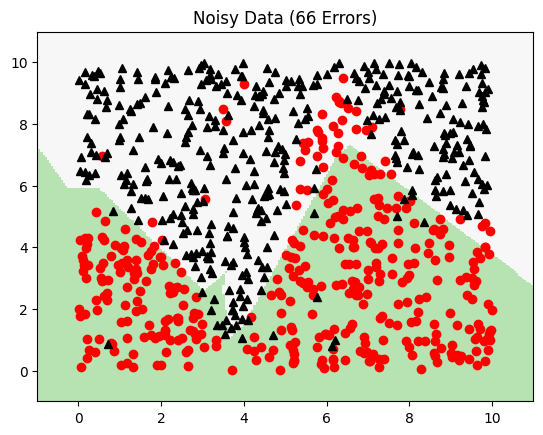

In [122]:
plot_boundary(x,y,model,f'Noisy Data (66 Errors)')